# Optimize GSAS-II instrument parameters: a simple example

We will use a LaB₆ reference measurement to improve the GSAS-II peak-shape parameters with easyXRD.

The steps are: subtract the Kapton background, integrate the detector image, load the LaB₆ structure, refine the peak shapes, and save the result.

Run the cells in order using a Python environment with easyXRD, GSAS-II, pyFAI, fabio, and matplotlib installed. Keep the five input files beside this notebook. No Materials Project API key is needed.

## 1. Import libraries and choose the input files

The `.poni` file provides the detector geometry and wavelength. The EDF mask marks bad pixels; the CIF provides the expected LaB₆ reflections.

In [1]:
import fabio
import numpy as np
import matplotlib.pyplot as plt
from easyxrd.core import exrd

%matplotlib inline
plt.rcParams["figure.constrained_layout.use"] = True

file_reference = "data/notebook_05/LaB6_in_Kapton.tiff"
file_background = "data/notebook_05/Kapton.tiff"
file_mask = "data/notebook_05/_mask.edf"
file_poni = "data/notebook_05/_geometry.poni"
file_structure = "data/notebook_05/LaB6.cif"
structure_name = 'LaB6'

background_scale = 1.0
q_range = [1, 10]  # Å⁻¹

INITIAL_PROFILE = dict(
    instprm_U=150.0, instprm_V=5.0, instprm_W=0.5,
    instprm_X=0.01, instprm_Y=0.01, instprm_Z=0.01, instprm_SHL=0.001,
    instprm_Zero=0.0, instprm_Polariz=0.0, instprm_Azimuth=0.0,
)



print("Initial instrument parameters:")
for name, value in INITIAL_PROFILE.items():
    parameter = name.removeprefix("instprm_").replace("SHL", "SH/L")
    print(f"{parameter:8s} = {value:.6g}")

Initial instrument parameters:
U        = 150
V        = 5
W        = 0.5
X        = 0.01
Y        = 0.01
Z        = 0.01
SH/L     = 0.001
Zero     = 0
Polariz  = 0
Azimuth  = 0


## 2. Subtract the background and inspect the image

Here we assume the reference and background have matching exposure and intensity normalization, so the background scale is 1. Adjust it if your acquisition conditions differ. Subtract in floating point and keep negative values.

Compare the reference image, Kapton background, and background-subtracted image side by side. Masked pixels appear in red. Each panel has its own intensity scale to make the rings and background visible. The same mask is passed to the integration step.

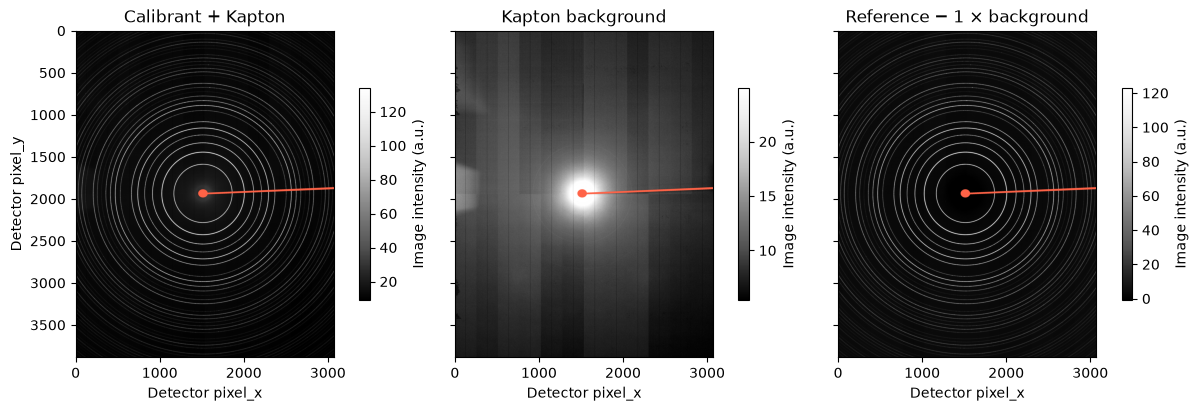

In [2]:
reference = fabio.open(file_reference).data.astype(np.float32)
background = fabio.open(file_background).data.astype(np.float32)
mask = fabio.open(file_mask).data != 0

assert reference.shape == background.shape == mask.shape
corrected = reference - background_scale * background

cmap = plt.get_cmap("Greys_r").copy()
cmap.set_bad("tomato")

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
images = [reference, background, corrected]
titles = ["Calibrant + Kapton", "Kapton background",
          f"Reference − {background_scale:g} × background"]

for ax, image, title in zip(axes, images, titles):
    low, high = np.percentile(image[~mask], [1, 99.5])
    im = ax.imshow(np.ma.array(image, mask=mask), cmap=cmap,
                   origin="upper", vmin=low, vmax=high)
    ax.set_title(title)
    ax.set_xlabel("Detector pixel_x")
    fig.colorbar(im, ax=ax, shrink=0.65, label="Image intensity (a.u.)")

axes[0].set_ylabel("Detector pixel_y")
plt.show()

## 3. Integrate the image and load the LaB₆ phase

Here we initiate exrd object, integrate the corrected image, and load structure from provided cif file. The integration range and bin spacing below are in q (Å⁻¹). The geometry and wavelength remain fixed throughout this example.

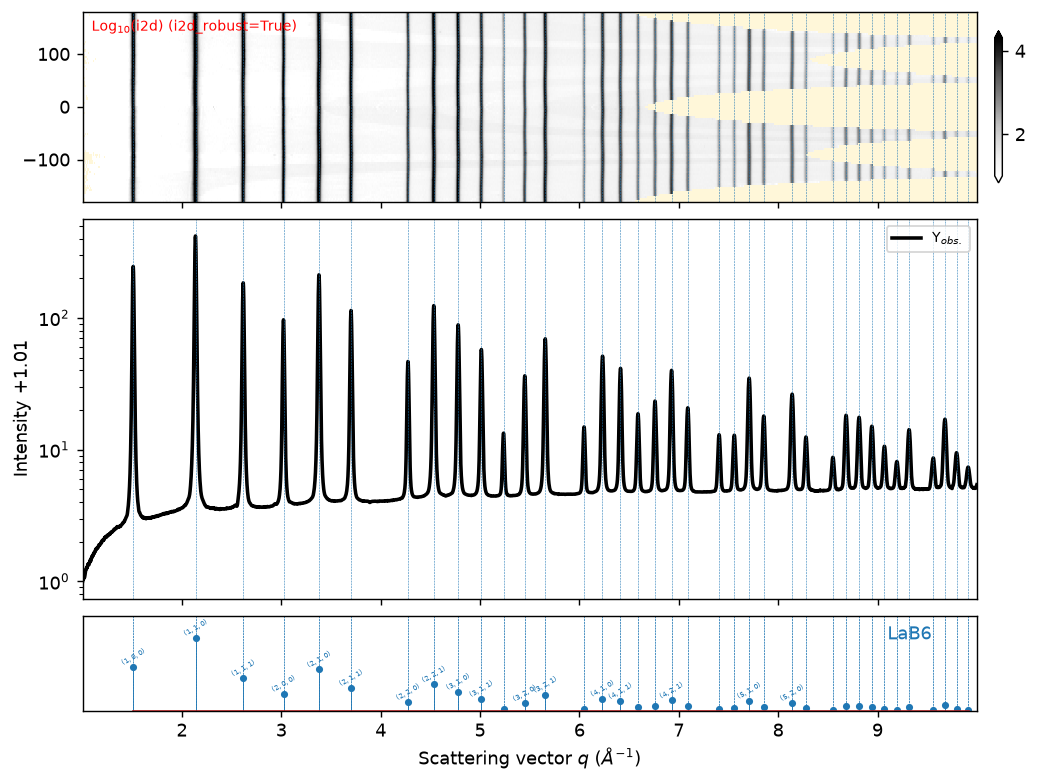

In [3]:
sample = exrd(i1d_ylogscale=True)

sample.load_xrd_data(
    from_img_array=corrected,
    poni_file=file_poni,
    mask=mask,
    radial_range=q_range,
    delta_q=0.001,
    plot=False,
)

sample.load_phases(
    [{"cif": file_structure, "label": structure_name}],
    plot=True,
)

## 4. Start GSAS-II and refine the background

easyXRD starts with a Le Bail fit: the crystal structure supplies reflection positions, while reflection intensities are fitted. We then fit a smooth background with ten coefficients.

Save the starting Rwp so we can compare it with the final result. Lower Rwp means a closer fit under the same data and weighting settings.

In [4]:
sample.setup_gsas2_refiner(plot=False,
    instprm_Polariz=INITIAL_PROFILE["instprm_Polariz"],
    instprm_Azimuth=INITIAL_PROFILE["instprm_Azimuth"],
    instprm_Zero=INITIAL_PROFILE["instprm_Zero"],
    instprm_U=INITIAL_PROFILE["instprm_U"],
    instprm_V=INITIAL_PROFILE["instprm_V"],
    instprm_W=INITIAL_PROFILE["instprm_W"],
    instprm_X=INITIAL_PROFILE["instprm_X"],
    instprm_Y=INITIAL_PROFILE["instprm_Y"],
    instprm_Z=INITIAL_PROFILE["instprm_Z"],
    instprm_SHL=INITIAL_PROFILE["instprm_SHL"],
    )
sample.refine_background(num_coeffs=10, plot=False)

starting_rwp = float(sample.ds.attrs["Rwp"])
print(f"Rwp before instrument refinement: {starting_rwp:.3f}%")

 ✅--1st refinement with LeBail is completed. Rwp/GoF is 61.778/1.781
 ✅--Background with 10 coeffs is refined. Rwp/GoF is now 17.177/0.495 (was 61.778(-72.19%)/1.781(-72.18%*))
Rwp before instrument refinement: 17.177%


## 5. Refine the peak-shape parameters individually

| Parameters | What they control |
|---|---|
| `U`, `V`, `W` | Gaussian peak widths |
| `X`, `Y`, `Z` | Lorentzian peak widths |
| `SH/L` | Peak asymmetry |

We refine one parameter at a time, then update the background. Two passes help the parameters settle before refining them together. This follows the approach in the original notebook.

In the tested easyXRD build, a trial needs at least a **1% relative decrease in GoF** to be retained. A “discarded” message means the previous fit was restored; it is not a program error. This threshold is a stopping policy, not proof of convergence.

In [5]:
parameters = ["U", "V", "W", "X", "Y", "Z", "SH/L"] 
# we don't refine Zero here as it is not common to refine it in sychrotron XRD with area detectors

for pass_number in range(4):
    print(f"\nPass {pass_number + 1}")
    for parameter in parameters:
        sample.refine_instrument_parameters(
            inst_pars_to_refine=[parameter], plot=False
        )
    sample.refine_background(num_coeffs=10, plot=False)


Pass 1
 ✅--Instrument parameter ['U'] is refined. Rwp/GoF is now 16.155/0.466 (was 17.177(-5.95%)/0.495(-6.00%))
 ✅--Instrument parameter ['V'] is refined. Rwp/GoF is now 14.699/0.424 (was 16.155(-9.01%)/0.466(-9.01%))
 ✅--Instrument parameter ['W'] is refined. Rwp/GoF is now 13.991/0.403 (was 14.699(-4.82%)/0.424(-4.82%))
 ✅--Instrument parameter ['X'] is refined. Rwp/GoF is now 13.496/0.389 (was 13.991(-3.53%)/0.403(-3.53%))
 ❌--Refinement discarded because of negative or nonfinite instrument peak widths (PWDR data.xy/Lorentzian width=-0.363673 at 2theta=16.4606 deg). 
      Previous project restored; profile data and phases unchanged.
 ❌--Refinement discarded because of insufficient GoF improvement (0.0435261%; requires a decrease of at least 0.1%). 
      Previous project restored; profile data and phases unchanged.
 ✅--Instrument parameter ['SH/L'] is refined. Rwp/GoF is now 12.189/0.351 (was 13.496(-9.68%)/0.389(-9.68%))
 ✅--Background with 10 coeffs is refined. Rwp/GoF is now 1

## 6. Refine the groups together and inspect the result

First refine each width group, then all seven profile parameters together. `Zero`, wavelength, and the calibrant cell are kept fixed.

Inspect the peak positions, widths, and difference curve. A lower Rwp alone does not establish a reliable instrument calibration. For this dataset, `X` and `Z` can be strongly correlated, so their individual values may not be uniquely determined.

 ❌--Refinement discarded because of insufficient GoF improvement (0.0393016%; requires a decrease of at least 0.1%). 
      Previous project restored; profile data and phases unchanged.
 ✅--Instrument parameter ['X', 'Y', 'Z'] is refined. Rwp/GoF is now 5.721/0.165 (was 5.725(-0.08%)/0.165(-0.11%!))
 ❌--Refinement discarded because of insufficient GoF improvement (0.03558%; requires a decrease of at least 0.1%). 
      Previous project restored; profile data and phases unchanged.
 ❌--Refinement discarded because of insufficient GoF improvement (-0.00954304%; requires a decrease of at least 0.1%). 
      Previous project restored; profile data and phases unchanged.
 ❌--Refinement discarded because of insufficient GoF improvement (0.03558%; requires a decrease of at least 0.1%). 
      Previous project restored; profile data and phases unchanged.
Rwp: 17.177% → 5.721%


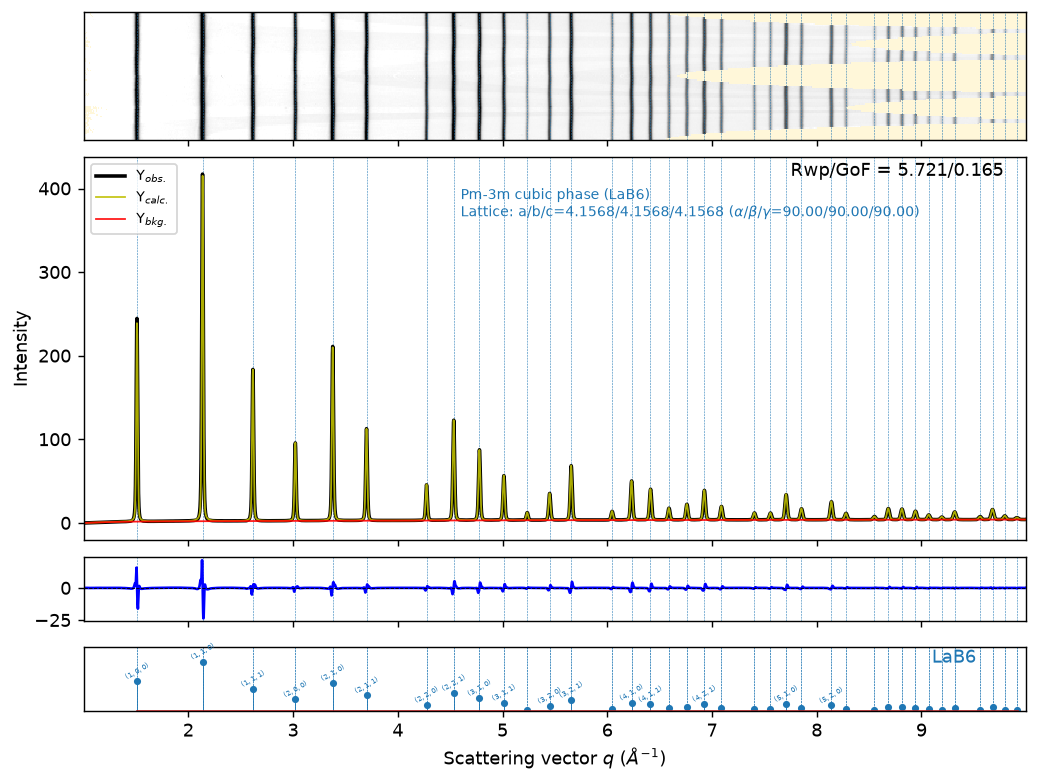

In [7]:
sample.refine_instrument_parameters(inst_pars_to_refine=["U", "V", "W"], plot=False)
sample.refine_instrument_parameters(inst_pars_to_refine=["X", "Y", "Z"], plot=False)
sample.refine_background(num_coeffs=10, plot=False)

sample.refine_instrument_parameters(inst_pars_to_refine=["U", "V", "W", "X", "Y", "Z", "SH/L"] , plot=False)
sample.refine_background(num_coeffs=10, plot=False)

final_rwp = float(sample.ds.attrs["Rwp"])
print(f"Rwp: {starting_rwp:.3f}% → {final_rwp:.3f}%")
sample.plot(i1d_ylogscale=False)

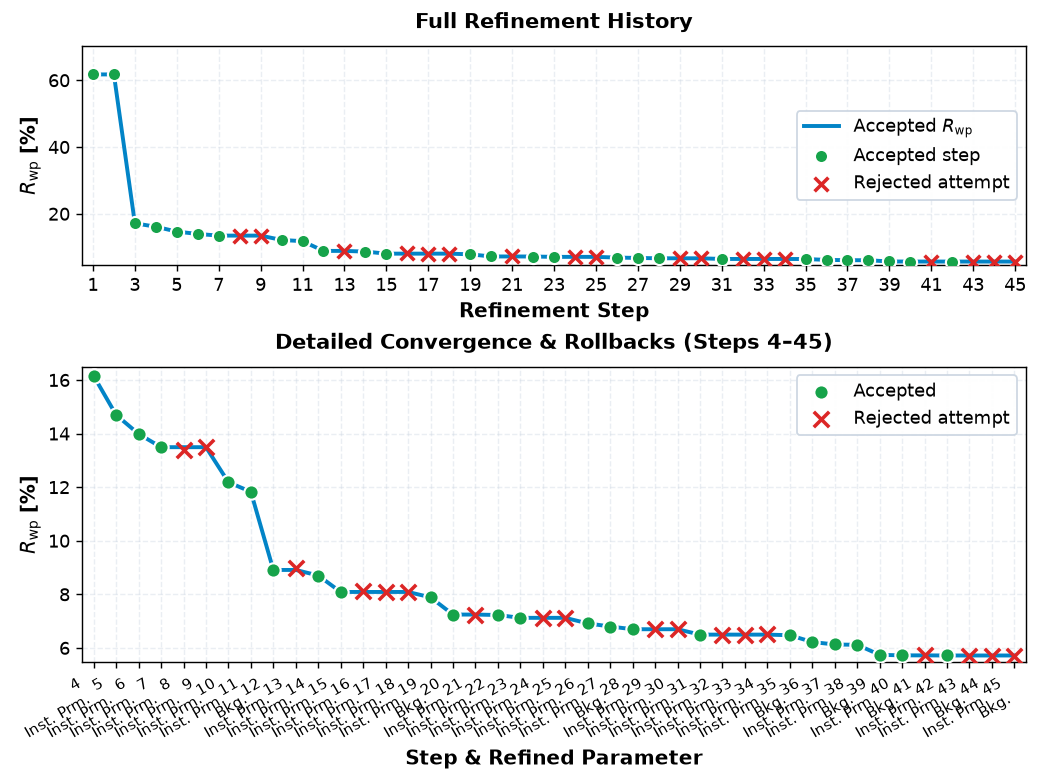

In [8]:
# Here we can plot the entire refinement history
sample.plot_refinement_history()

## 7. Save the optimized instrument parameters

The GPX stores the complete GSAS-II project, including the refined instrument values. To use it in another easyXRD analysis, pass its path to `setup_gsas2_refiner(instprm_from_gpx="LaB6_optimized.gpx")` after loading your new data and phases.

In [9]:
output_file = "data/notebook_05/LaB6_optimized.gpx"
sample.export_gpx_to(output_file)

instrument = sample.gpx.histograms()[0]["Instrument Parameters"][0]
print(f"Saved: {output_file}\n")

print('Final instrument parameters:')
for parameter in parameters:
    initial = INITIAL_PROFILE["instprm_" + parameter.replace("/", "")]
    print(f"{parameter:5s} = {instrument[parameter][1]:.6g} (initial: {initial:.6g})")

Saved: data/notebook_05/LaB6_optimized.gpx

Final instrument parameters:
U     = 144.521 (initial: 150)
V     = -1.00394 (initial: 5)
W     = 0.958907 (initial: 0.5)
X     = 0.424254 (initial: 0.01)
Y     = -3.14631 (initial: 0.01)
Z     = 0.125805 (initial: 0.01)
SH/L  = 0.0040382 (initial: 0.001)


### Before applying this calibration to other samples

Use the same detector geometry, wavelength. Check the result against another reference measurement, and ensure that calibrant size/strain broadening and the asymmetry model are appropriate for your experiment.

This simple integration path does not propagate measured intensity uncertainties into GSAS-II. Treat Rwp and GoF as fit comparisons; a GoF below 1 does not validate the uncertainty model.